<a href="https://colab.research.google.com/github/romanotancredi/equity-investment-research-portfolio/blob/main/02_portfolio_construction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 📈 Phase 2 — Global Equity Portfolio Construction

## Investment Objective

Construct a hypothetical global equity portfolio using three
regional equity ETFs and evaluate its performance against
a global equity benchmark.

### Portfolio Allocation
- VTI: 60% — US Equities
- VEA: 30% — Developed Markets ex-US
- VWO: 10% — Emerging Markets

### Benchmark
- VT: Vanguard Total World Stock ETF

### Methodology
- Historical adjusted ETF prices
- Daily portfolio returns
- Constant portfolio weights (daily rebalancing)
- Cumulative performance and benchmark comparison

### Data Source
Yahoo Finance, downloaded and cleaned in Phase 1.
Historical dataset stored in the project's GitHub repository.


In [6]:

# ---------------------------------------------------------
# PHASE 2 - STEP 1: IMPORT LIBRARIES AND LOAD SHARED DATA
# ---------------------------------------------------------

# Import pandas for working with financial time series.
# pd is simply a shorter alias for pandas.

import pandas as pd

# Import numpy for mathematical and numerical operations.
# We will use it to validate weights and calculate risk.

import numpy as np

# Import matplotlib for creating investment charts.

import matplotlib.pyplot as plt


# ---------------------------------------------------------
# DEFINE OUR SHARED DATA SOURCE
# ---------------------------------------------------------

# This URL points directly to the CSV stored on GitHub.
# Unlike a normal GitHub page, the raw URL returns the
# actual file contents, which pandas can read directly.

data_url = (
    "https://raw.githubusercontent.com/romanotancredi/"
    "equity-investment-research-portfolio/refs/heads/main/"
    "01-equity-performance-and-risk/data/etf_prices.csv"
)


# ---------------------------------------------------------
# READ THE CSV FILE
# ---------------------------------------------------------

# pd.read_csv() converts the CSV into a pandas DataFrame.
#
# index_col="Date":
# Uses the Date column as the DataFrame's index.
#
# parse_dates=["Date"]:
# Converts dates stored as text into datetime values.
# This allows Python to perform time-series calculations.

prices = pd.read_csv(
    data_url,
    index_col="Date",
    parse_dates=["Date"]
)


# ---------------------------------------------------------
# VALIDATE THE DATASET
# ---------------------------------------------------------

# Define the ETFs that should exist in the dataset.

tickers = ["VTI", "VEA", "VWO", "VT"]

# Select and order the columns consistently.

prices = prices[tickers]

# Sort the observations from oldest to newest.

prices = prices.sort_index()

# Check whether the dataset contains missing values.
# isna() identifies missing observations.
# sum() counts them for each ETF.

print("Missing values:")
print(prices.isna().sum())

# Remove rows with missing prices, if any.

prices = prices.dropna()

# Check the number of observations and date range.
# len() returns the number of rows.

print("\nNumber of observations:", len(prices))
print("Start date:", prices.index.min())
print("End date:", prices.index.max())

# Display the first five observations.

display(prices.head())


Missing values:
VTI    0
VEA    0
VWO    0
VT     0
dtype: int64

Number of observations: 1717
Start date: 2020-01-02 00:00:00
End date: 2026-10-30 00:00:00


,VTI,VEA,VWO,VT
Date,,,,
2020-01-02,149.778320,36.584690,37.796169,71.800972
2020-01-03,148.825058,36.139923,37.123756,71.151497
2020-01-06,149.333511,36.263466,37.057343,71.414833
2020-01-07,148.979431,36.205811,37.040737,71.195404
2020-01-08,149.714813,36.255238,37.206779,71.485016


In [7]:

# ---------------------------------------------------------
# PHASE 2 - STEP 2: CALCULATE DAILY ETF RETURNS
# ---------------------------------------------------------

# Convert historical prices into daily percentage returns.
#
# pct_change() compares each price with the previous price.
#
# Formula:
# Return(t) = Price(t) / Price(t-1) - 1

daily_returns = prices.pct_change()

# Remove the first observation because its daily return
# cannot be calculated without a previous price.

daily_returns = daily_returns.dropna()

# Display the first five daily return observations.

display(daily_returns.head())


,VTI,VEA,VWO,VT
Date,,,,
2020-01-03,-0.006364,-0.012157,-0.017791,-0.009045
2020-01-06,0.003416,0.003418,-0.001789,0.003701
2020-01-07,-0.002371,-0.001590,-0.000448,-0.003073
2020-01-08,0.004936,0.001365,0.004483,0.004068
2020-01-09,0.006246,0.004089,0.005131,0.004911


In [4]:

# ---------------------------------------------------------
# PHASE 2 - STEP 3: DEFINE PORTFOLIO WEIGHTS
# ---------------------------------------------------------

# Create a pandas Series containing portfolio allocations.
# Each ETF ticker is associated with its target weight.

weights = pd.Series({
    "VTI": 0.60,  # US equity allocation: 60%
    "VEA": 0.30,  # Developed markets ex-US: 30%
    "VWO": 0.10   # Emerging markets: 10%
})

# Verify that the portfolio is fully invested.
#
# weights.sum() adds all portfolio weights.
#
# np.isclose() checks whether the sum is approximately 1,
# accounting for small floating-point rounding differences.
#
# assert raises an error if the condition is not satisfied.

assert np.isclose(weights.sum(), 1.0), \
    "Error: Portfolio weights must sum to 100%"

# Display the portfolio weights.

display(weights)


,0
VTI,0.6
VEA,0.3
VWO,0.1


In [5]:

# ---------------------------------------------------------
# PHASE 2 - STEP 4: CALCULATE DAILY PORTFOLIO RETURNS
# ---------------------------------------------------------

# Select only the ETFs included in our portfolio.
#
# weights.index retrieves the ETF tickers stored in
# our weights Series: VTI, VEA and VWO.
#
# VT is excluded because it represents our benchmark.

portfolio_asset_returns = daily_returns[weights.index]


# Calculate the weighted return of the portfolio.
#
# dot() performs a dot product between two objects:
# 1. Each ETF's daily returns (DataFrame)
# 2. The corresponding portfolio weights (Series)
#
# For each day, Python calculates:
#
# Portfolio Return =
# (VTI Return * 0.60) +
# (VEA Return * 0.30) +
# (VWO Return * 0.10)
#
# The result is a Series containing one portfolio
# return for each trading day.

portfolio_returns = portfolio_asset_returns.dot(weights)


# Extract the benchmark's daily returns.
#
# VT represents the global equity benchmark proxy.

benchmark_returns = daily_returns["VT"]


# Combine portfolio and benchmark returns into one DataFrame.
#
# pd.DataFrame() creates a table from the two Series.
# Each row represents a trading day.

performance = pd.DataFrame({
    "Portfolio": portfolio_returns,
    "Benchmark": benchmark_returns
})


# Display the first five daily return observations.

display(performance.head())


,Portfolio,Benchmark
Date,,
2020-01-03,-0.009245,-0.009045
2020-01-06,0.002897,0.003701
2020-01-07,-0.001944,-0.003073
2020-01-08,0.003819,0.004068
2020-01-09,0.005487,0.004911


In [8]:

# ---------------------------------------------------------
# PHASE 2 - STEP 5: CALCULATE CUMULATIVE PERFORMANCE
# ---------------------------------------------------------

# Convert daily returns into daily growth factors.
#
# Example:
# +2% return becomes 1.02
# -3% return becomes 0.97

growth_factors = 1 + performance


# Calculate cumulative growth.
#
# cumprod() means "cumulative product".
#
# It multiplies each day's growth factor by all
# previous growth factors.
#
# Unlike cumsum(), which adds values together,
# cumprod() correctly accounts for compounding.

cumulative_performance = growth_factors.cumprod()


# Multiply by 100 to simulate an initial investment of $100.

cumulative_performance = cumulative_performance * 100


# Display the last five observations.
#
# tail() returns the last rows of a DataFrame.
# This lets us inspect the latest portfolio values.

display(cumulative_performance.tail())


,Portfolio,Benchmark
Date,,
2026-10-26,221.561105,218.158606
2026-10-27,223.042495,219.620986
2026-10-28,224.000169,220.456616
2026-10-29,223.629720,220.010951
2026-10-30,219.852348,216.334121


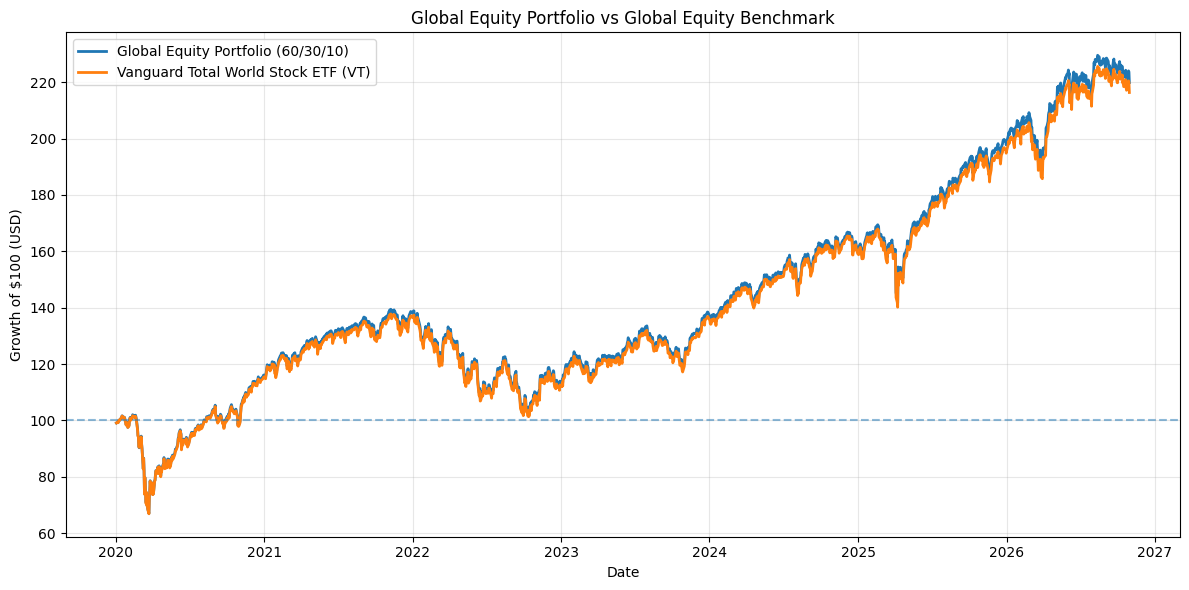

In [9]:

# ---------------------------------------------------------
# PHASE 2 - STEP 6: VISUALISE CUMULATIVE PERFORMANCE
# ---------------------------------------------------------

# Create a new chart measuring 12 by 6 inches.
#
# figsize controls the physical dimensions of the chart.

plt.figure(figsize=(12, 6))


# Plot our portfolio's cumulative performance.
#
# The first argument represents dates (X-axis).
# The second represents portfolio values (Y-axis).
#
# label provides the series name in the legend.
# linewidth controls how thick the line appears.

plt.plot(
    cumulative_performance.index,
    cumulative_performance["Portfolio"],
    label="Global Equity Portfolio (60/30/10)",
    linewidth=2
)


# Plot the benchmark's cumulative performance.

plt.plot(
    cumulative_performance.index,
    cumulative_performance["Benchmark"],
    label="Vanguard Total World Stock ETF (VT)",
    linewidth=2
)


# Add a horizontal reference line at 100.
#
# axhline() creates a horizontal line.
# linestyle="--" makes it dashed.

plt.axhline(
    y=100,
    linestyle="--",
    alpha=0.5
)


# Add chart title and axis descriptions.

plt.title("Global Equity Portfolio vs Global Equity Benchmark")
plt.xlabel("Date")
plt.ylabel("Growth of $100 (USD)")


# Display legend and grid.

plt.legend()
plt.grid(alpha=0.3)


# Automatically adjust chart spacing to avoid overlap.

plt.tight_layout()


# Render the chart.

plt.show()


In [10]:

# ---------------------------------------------------------
# PHASE 2 - STEP 7: CALCULATE ACTIVE RETURNS
# ---------------------------------------------------------

# Calculate daily active returns.
#
# A positive value means portfolio outperformance
# relative to the benchmark for that trading day.
#
# A negative value means underperformance.

performance["Active Return"] = (
    performance["Portfolio"] - performance["Benchmark"]
)


# Calculate the arithmetic average daily active return.
#
# mean() returns the average value of a Series.

average_daily_active_return = performance["Active Return"].mean()


# Express the result as a percentage.
#
# Python stores returns as decimals, so multiplying
# by 100 converts them into percentage values.

print(
    "Average Daily Active Return:",
    round(average_daily_active_return * 100, 4),
    "%"
)


# Calculate the compounded total return for each series.
#
# iloc[-1] selects the last observation of a DataFrame.
# Dividing by 100 converts the terminal growth index
# back into a growth factor.

total_returns = (
    cumulative_performance.iloc[-1] / 100 - 1
)


# Calculate the difference between the two total returns.
#
# This is the absolute difference in compounded returns,
# expressed in percentage points.
#
# It is not the same as a geometrically linked
# cumulative active-return series.

total_return_difference = (
    total_returns["Portfolio"] - total_returns["Benchmark"]
)


# Display the results in percentage terms.

print(
    "Portfolio Total Return:",
    round(total_returns["Portfolio"] * 100, 2),
    "%"
)

print(
    "Benchmark Total Return:",
    round(total_returns["Benchmark"] * 100, 2),
    "%"
)

print(
    "Total Return Difference:",
    round(total_return_difference * 100, 2),
    "percentage points"
)


Average Daily Active Return: 0.001 %
Portfolio Total Return: 119.85 %
Benchmark Total Return: 116.33 %
Total Return Difference: 3.52 percentage points


In [11]:

# ---------------------------------------------------------
# STEP 8: FIND MAXIMUM AND MINIMUM DAILY ACTIVE RETURNS
# ---------------------------------------------------------

# Select the daily active return series.
# Active Return = Portfolio Return - Benchmark Return

active_returns = performance["Active Return"]

# max() returns the highest value in the Series.
# This is the largest daily outperformance.

max_active_return = active_returns.max()

# idxmax() returns the index (date) where the maximum occurred.

max_active_date = active_returns.idxmax()

# min() returns the lowest value in the Series.
# This is the largest daily underperformance.

min_active_return = active_returns.min()

# idxmin() returns the date where the minimum occurred.

min_active_date = active_returns.idxmin()

# Display the results.
# Multiply by 100 to convert decimal returns into percentages.
# A difference in returns is expressed in percentage points.

print("Maximum daily outperformance:",
      round(max_active_return * 100, 2), "percentage points")

print("Date:", max_active_date.date())

print("Maximum daily underperformance:",
      round(min_active_return * 100, 2), "percentage points")

print("Date:", min_active_date.date())


Maximum daily outperformance: 0.43 percentage points
Date: 2025-04-09
Maximum daily underperformance: -0.75 percentage points
Date: 2020-03-17


In [12]:

# ---------------------------------------------------------
# STEP 9: MAXIMUM ABSOLUTE DAILY ACTIVE RETURN
# ---------------------------------------------------------

# abs() converts negative values into positive values.
# For example, -0.02 becomes +0.02.

absolute_active_returns = active_returns.abs()

# Find the date of the largest absolute difference.

max_difference_date = absolute_active_returns.idxmax()

# Retrieve the original signed active return on that date.
# loc[] selects an observation using its index label.

max_difference = active_returns.loc[max_difference_date]

print(
    "Largest absolute daily difference:",
    round(abs(max_difference) * 100, 2),
    "percentage points"
)

print("Date:", max_difference_date.date())

print(
    "Direction:",
    "Outperformance" if max_difference > 0 else "Underperformance"
)


Largest absolute daily difference: 0.75 percentage points
Date: 2020-03-17
Direction: Underperformance


In [13]:

# ---------------------------------------------------------
# STEP 10: MAXIMUM CUMULATIVE PERFORMANCE DIFFERENCE
# ---------------------------------------------------------

# Calculate the cumulative return of each investment.
# We divide by 100 and subtract 1 to obtain returns.

cumulative_returns = cumulative_performance / 100 - 1

# Calculate the difference between cumulative returns.
# This measures the cumulative return gap in percentage points.

cumulative_return_gap = (
    cumulative_returns["Portfolio"]
    - cumulative_returns["Benchmark"]
)

# Find the maximum positive gap and corresponding date.

max_gap = cumulative_return_gap.max()
max_gap_date = cumulative_return_gap.idxmax()

# Find the largest negative gap and corresponding date.

min_gap = cumulative_return_gap.min()
min_gap_date = cumulative_return_gap.idxmin()

print(
    "Maximum cumulative outperformance:",
    round(max_gap * 100, 2),
    "percentage points",
    "on", max_gap_date.date()
)

print(
    "Maximum cumulative underperformance:",
    round(min_gap * 100, 2),
    "percentage points",
    "on", min_gap_date.date()
)


Maximum cumulative outperformance: 4.25 percentage points on 2026-06-26
Maximum cumulative underperformance: -0.14 percentage points on 2020-02-28
